#  5-Fold Cross-Validation (4 Models, Class-Weighted)




**What it runs**
1. **Distribution check:** class and source counts, class weights, fold stratification proof.
2. **Baselines:** majority class and TF-IDF + Logistic Regression, on the same folds.
3. **5-fold CV** for AraBERT, MARBERT, MARBERTv2, SaudiBERT (class-weighted loss, early stopping on an inner dev split).
4. **Results:** mean ± std over folds, out-of-fold macro-F1 with 95% bootstrap CI, per-class and per-source scores, confusion matrix.
5. **Leave-one-source-out (LOSO):** train on two sources, test on the third (tests that models learn meaning, not source style).
6. **Ablation:** gold only vs. gold + balanced pseudo-labels, regenerated **inside each fold** so nothing leaks into the test fold.

**How the label distribution is handled**
- Folds are stratified by **source + label**, so every fold keeps the same class and source mix.
- The loss is **class-weighted** (inverse frequency, computed from each fold's training data only).
- The main metric is **macro-F1** (not accuracy), because Negative is the largest class (36.5%).
- Dev data for early stopping is carved from the training part of each fold. **Test folds are never used for training or tuning.**

Rough GPU time (T4): about 30 to 40 min for the 4-model CV, about 15 min for LOSO, about 25 min for the ablation. Set the flags below to skip parts. Results are cached, so you can re-run after a disconnect (use `USE_DRIVE = True`).

In [ ]:
!pip install -q "transformers>=4.46,<5" "datasets>=2.19" accelerate scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import os, re, json, random, zipfile, warnings, platform, hashlib, pickle, gc, shutil, tempfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:
    display = print

def set_all_seeds(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("WARNING: no GPU. In Colab: Runtime > Change runtime type > T4 GPU")

Device: cuda


## 1. Configuration

In [ ]:
GOLD_FILE = "manual_gold.csv"
POOL_FILE = "merged_clean.csv"        # only needed when RUN_ABLATION = True

LABELS = ["Positive", "Negative", "Neutral", "Ironic"]

MODELS = {
    "AraBERT":   "aubmindlab/bert-base-arabertv02-twitter",
    "MARBERT":   "UBC-NLP/MARBERT",
    "MARBERTv2": "UBC-NLP/MARBERTv2",
    "SaudiBERT": "faisalq/SaudiBERT",
}
MODELS_TO_RUN = list(MODELS)          # e.g. ["AraBERT"] for a quick test run

K_FOLDS, SEED, DEV_FRAC = 5, 42, 0.10
MAX_LEN, LR, BATCH, EPOCHS, PATIENCE = 128, 2e-5, 16, 4, 2
USE_CLASS_WEIGHTS = True

RUN_LOSO     = True                   # leave-one-source-out
RUN_ABLATION = True                   # gold vs gold + pseudo-labels (self-training inside each fold)
ABLATION_MODEL  = "AraBERT"
PSEUDO_MIN_CONF = 0.80                # minimum confidence for a pseudo-label
PSEUDO_PER_CELL = 150                 # max pseudo-labels per (source, class) cell: keeps classes and sources balanced

N_BOOT = 1000
USE_DRIVE = False                     # True = keep outputs and cache on Google Drive (safe against disconnects)

OUT_DIR = "outputs"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/gold_cv_outputs"
CACHE_DIR = os.path.join(OUT_DIR, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)

CFG = dict(models={k: MODELS[k] for k in MODELS_TO_RUN}, k=K_FOLDS, seed=SEED, dev=DEV_FRAC, max_len=MAX_LEN, lr=LR,
           batch=BATCH, epochs=EPOCHS, patience=PATIENCE, cw=USE_CLASS_WEIGHTS, abl=RUN_ABLATION, abl_model=ABLATION_MODEL,
           conf=PSEUDO_MIN_CONF, cell=PSEUDO_PER_CELL)
CFG_TAG = hashlib.md5(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:8]   # cache key: changes when settings change
print("Config tag:", CFG_TAG)

Config tag: 48215ba6


## 2. Load the gold set and check the distribution

In [ ]:
def ensure_files(names):
    missing = [n for n in names if not os.path.exists(n)]
    if missing:
        try:
            from google.colab import files
            print("Please upload:", missing); files.upload()
        except ImportError:
            raise FileNotFoundError(f"Missing files: {missing}")

def download(path):
    try:
        from google.colab import files
        files.download(path)
    except Exception:
        print("Saved at:", path)

ensure_files([GOLD_FILE])
gold = pd.read_csv(GOLD_FILE, encoding="utf-8-sig")
gold = gold[["id", "source", "text", "label"]].dropna(subset=["label", "text"]).drop_duplicates("id").reset_index(drop=True)
bad = gold[~gold.label.isin(LABELS)]
assert len(bad) == 0, f"Unexpected labels: {bad.label.unique()}"
print(f"Gold rows: {len(gold):,}")

dist = gold.label.value_counts().reindex(LABELS)
weights = len(gold) / (len(LABELS) * dist)
print("\nClass distribution (this is the distribution the whole evaluation acknowledges):")
display(pd.DataFrame({"count": dist, "percent": (dist / len(gold) * 100).round(1), "class_weight": weights.round(2)}))
print("Label by source:")
display(pd.crosstab(gold.source, gold.label, margins=True).reindex(columns=LABELS + ["All"]))
maj = dist.idxmax()
print(f"Majority-class baseline: always '{maj}' -> accuracy {dist.max() / len(gold):.3f}, macro-F1 is near 0.14 (that is why macro-F1 is the main metric)")

# ---- stratified folds on (source, label)
gold["strata"] = gold.source + "|" + gold.label
use_strata = gold.strata.value_counts().min() >= K_FOLDS
strat = gold.strata if use_strata else gold.label
print("Stratifying folds by:", "source + label" if use_strata else "label only (some source/label cells are smaller than K)")
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
gold["fold"] = -1
for k, (_, te_idx) in enumerate(skf.split(gold, strat)):
    gold.loc[te_idx, "fold"] = k
print("\nTest-fold composition (each fold keeps the same class mix):")
display(pd.crosstab(gold.fold, gold.label).reindex(columns=LABELS))
display(pd.crosstab(gold.fold, gold.source))
gold[["id", "fold"]].to_csv(f"{OUT_DIR}/fold_assignments.csv", index=False)

def fold_split(k):
    te = gold[gold.fold == k]
    trv = gold[gold.fold != k]
    tr, dv = train_test_split(trv, test_size=DEV_FRAC, stratify=trv.label, random_state=SEED + k)
    return tr, dv, te

Please upload: ['manual_gold.csv']


Saving manual_gold.csv to manual_gold.csv
Gold rows: 1,200

Class distribution (this is the distribution the whole evaluation acknowledges):


,count,percent,class_weight
label,,,
Positive,213,17.8,1.41
Negative,438,36.5,0.68
Neutral,221,18.4,1.36
Ironic,328,27.3,0.91


Label by source:


label,Positive,Negative,Neutral,Ironic,All
source,,,,,
Bank,61,225,140,46,472
Sa7r,60,68,42,238,408
Telecom,92,145,39,44,320
All,213,438,221,328,1200


Majority-class baseline: always 'Negative' -> accuracy 0.365, macro-F1 is near 0.14 (that is why macro-F1 is the main metric)
Stratifying folds by: source + label

Test-fold composition (each fold keeps the same class mix):


label,Positive,Negative,Neutral,Ironic
fold,,,,
0,42,88,44,66
1,42,88,44,66
2,43,88,44,65
3,43,87,44,66
4,43,87,45,65


source,Bank,Sa7r,Telecom
fold,,,
0,94,82,64
1,94,82,64
2,94,82,64
3,95,81,64
4,95,81,64


## 3. Helpers

In [ ]:
def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labs = [l for l in LABELS if l in set(y_true)]          # macro over classes present in y_true
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=labs, average="macro", zero_division=0)}

def bootstrap_ci(y_true, y_pred, n=N_BOOT, seed=SEED):
    rng = np.random.RandomState(seed)
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    vals = []
    for _ in range(n):
        idx = rng.randint(0, len(yt), len(yt))
        vals.append(metrics(yt[idx], yp[idx])["macro_f1"])
    return np.percentile(vals, [2.5, 97.5])

def cached(tag, fn):
    path = os.path.join(CACHE_DIR, f"{CFG_TAG}_{tag}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    out = fn()
    with open(path, "wb") as f:
        pickle.dump(out, f)
    return out

def build_oof(probs_by_fold):
    parts = []
    for k, P in probs_by_fold.items():
        d = gold[gold.fold == k][["id", "source", "label", "fold"]].copy()
        d["pred"] = [LABELS[i] for i in P.argmax(1)]
        for j, l in enumerate(LABELS):
            d[f"p_{l}"] = P[:, j]
        parts.append(d)
    return pd.concat(parts).sort_values("id").reset_index(drop=True)

oof, fold_scores = {}, []
def record(name, probs_by_fold):
    d = build_oof(probs_by_fold)
    oof[name] = d
    d.to_csv(f"{OUT_DIR}/oof_{name}.csv", index=False, encoding="utf-8-sig")
    for k in sorted(probs_by_fold):
        f = d[d.fold == k]
        fold_scores.append({"model": name, "fold": k, **metrics(f.label, f.pred)})
    m = metrics(d.label, d.pred)
    print(f"  {name}: out-of-fold accuracy {m['accuracy']:.3f} | macro-F1 {m['macro_f1']:.3f}")

## 4. Baselines (same folds)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

maj_probs, lr_probs = {}, {}
for k in range(K_FOLDS):
    tr, dv, te = fold_split(k)
    trv = pd.concat([tr, dv])
    P = np.zeros((len(te), len(LABELS)), dtype=np.float32)
    P[:, LABELS.index(trv.label.value_counts().idxmax())] = 1.0
    maj_probs[k] = P
    pipe = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=2000, class_weight="balanced"))
    pipe.fit(trv.text, trv.label)
    raw = pipe.predict_proba(te.text)
    P2 = np.zeros((len(te), len(LABELS)), dtype=np.float32)
    for ci, c in enumerate(pipe.classes_):
        P2[:, LABELS.index(c)] = raw[:, ci]
    lr_probs[k] = P2

print("Baselines:")
record("Majority", maj_probs)
record("TFIDF_LR", lr_probs)

Baselines:
  Majority: out-of-fold accuracy 0.365 | macro-F1 0.134
  TFIDF_LR: out-of-fold accuracy 0.692 | macro-F1 0.667


## 5. Model training function
Class-weighted cross-entropy, AdamW, early stopping on the inner dev split (macro-F1). It returns class probabilities for every evaluation set you pass in.

In [ ]:
# [HF]
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, EarlyStoppingCallback)
from datasets import Dataset

label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = None if class_weights is None else torch.tensor(class_weights, dtype=torch.float)

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        logits = outputs.logits
        w = None if self.class_weights is None else self.class_weights.to(logits.device)
        loss = torch.nn.functional.cross_entropy(logits.float(), labels, weight=w)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro")}

def fit_predict(model_name, train_df, dev_df, eval_sets, seed):
    """Fine-tune on train_df (early stop on dev_df); return {name: probs} for each DataFrame in eval_sets."""
    set_all_seeds(seed)
    tok = AutoTokenizer.from_pretrained(model_name)

    def to_ds(df):
        d = {"text": df.text.tolist()}
        if "label" in df.columns and df["label"].notna().all():
            d["labels"] = [label2id[l] for l in df.label]
        return Dataset.from_dict(d).map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                                        batched=True, remove_columns=["text"])

    counts = train_df.label.value_counts().reindex(LABELS).fillna(0).values
    cw = len(train_df) / (len(LABELS) * np.clip(counts, 1, None)) if USE_CLASS_WEIGHTS else None

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(LABELS), id2label=id2label, label2id=label2id)
    tmp = tempfile.mkdtemp()
    args = TrainingArguments(
        output_dir=tmp, learning_rate=LR, per_device_train_batch_size=BATCH, per_device_eval_batch_size=64,
        num_train_epochs=EPOCHS, weight_decay=0.01, eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
        save_total_limit=1, seed=seed, fp16=torch.cuda.is_available(), report_to="none", logging_steps=50,
        disable_tqdm=True)
    trainer = WeightedTrainer(model=model, args=args, train_dataset=to_ds(train_df), eval_dataset=to_ds(dev_df),
                              processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                              compute_metrics=compute_metrics, class_weights=cw,
                              callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)])
    trainer.train()

    outs = {}
    for name, df in eval_sets.items():
        logits = trainer.predict(to_ds(df)).predictions
        if isinstance(logits, tuple):
            logits = logits[0]
        outs[name] = torch.softmax(torch.tensor(logits), dim=-1).numpy()

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    shutil.rmtree(tmp, ignore_errors=True)
    return outs

## 6. Main 5-fold cross-validation
One model at a time. Each (model, fold) result is cached, so a disconnect only costs the run in progress.

In [ ]:
pool, pool_probs = None, {}
if RUN_ABLATION:
    ensure_files([POOL_FILE])
    _m = pd.read_csv(POOL_FILE, encoding="utf-8-sig")
    pool = _m[~_m.id.isin(gold.id)][["id", "source", "text"]].reset_index(drop=True)
    print(f"Unlabeled pool for the ablation: {len(pool):,} rows")

for name in MODELS_TO_RUN:
    print(f"\n=== {name} ({MODELS[name]})")
    probs_by_fold = {}
    for k in range(K_FOLDS):
        tr, dv, te = fold_split(k)
        eval_sets = {"test": te}
        if RUN_ABLATION and name == ABLATION_MODEL:
            eval_sets["pool"] = pool            # pseudo-labels for the ablation come from THIS fold's model
        outs = cached(f"{name}_fold{k}", lambda: fit_predict(MODELS[name], tr, dv, eval_sets, seed=SEED + k))
        probs_by_fold[k] = outs["test"]
        if "pool" in outs:
            pool_probs[k] = outs["pool"]
        print(f"  fold {k}: macro-F1 {metrics(te.label, [LABELS[i] for i in outs['test'].argmax(1)])['macro_f1']:.3f}")
    record(name, probs_by_fold)

Please upload: ['merged_clean.csv']


Saving merged_clean.csv to merged_clean.csv
Unlabeled pool for the ablation: 39,682 rows

=== AraBERT (aubmindlab/bert-base-arabertv02-twitter)


tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (145 outputs left out)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 3, 'bos_token_id': 2}.


{'loss': 1.0633, 'grad_norm': 5.8624420166015625, 'learning_rate': 1.5462962962962966e-05, 'epoch': 0.9259259259259259}
{'eval_loss': 0.7415428161621094, 'eval_accuracy': 0.78125, 'eval_macro_f1': 0.7534593714117868, 'eval_runtime': 0.1069, 'eval_samples_per_second': 898.066, 'eval_steps_per_second': 18.71, 'epoch': 1.0}
{'loss': 0.5682, 'grad_norm': 6.494277000427246, 'learning_rate': 1.0833333333333334e-05, 'epoch': 1.8518518518518519}
{'eval_loss': 0.6165999174118042, 'eval_accuracy': 0.7916666666666666, 'eval_macro_f1': 0.7812568431237745, 'eval_runtime': 0.1129, 'eval_samples_per_second': 850.256, 'eval_steps_per_second': 17.714, 'epoch': 2.0}
{'loss': 0.3226, 'grad_norm': 7.944333553314209, 'learning_rate': 6.203703703703704e-06, 'epoch': 2.7777777777777777}
{'eval_loss': 0.5999118685722351, 'eval_accuracy': 0.8125, 'eval_macro_f1': 0.7957551054018446, 'eval_runtime': 0.1135, 'eval_samples_per_second': 845.537, 'eval_steps_per_second': 17.615, 'epoch': 3.0}
{'loss': 0.2437, 'grad

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

  fold 4: macro-F1 0.752
  SaudiBERT: out-of-fold accuracy 0.802 | macro-F1 0.787


## 7. Results

MAIN RESULTS (5-fold CV on the 1,200 manual labels):


,model,accuracy (mean±std),macro-F1 (mean±std),OOF macro-F1,95% CI
0,Majority,0.365 ± 0.002,0.134 ± 0.001,0.134,"[0.126, 0.141]"
1,TFIDF_LR,0.692 ± 0.016,0.666 ± 0.016,0.667,"[0.642, 0.695]"
2,AraBERT,0.784 ± 0.025,0.771 ± 0.027,0.772,"[0.747, 0.797]"
3,MARBERT,0.791 ± 0.024,0.775 ± 0.023,0.776,"[0.749, 0.800]"
4,MARBERTv2,0.771 ± 0.033,0.755 ± 0.035,0.756,"[0.731, 0.780]"
5,SaudiBERT,0.802 ± 0.030,0.787 ± 0.031,0.787,"[0.761, 0.811]"



Per-class F1 (out-of-fold):


,Majority,TFIDF_LR,AraBERT,MARBERT,MARBERTv2,SaudiBERT
Positive,0.000,0.736,0.830,0.857,0.833,0.848
Negative,0.535,0.754,0.850,0.850,0.836,0.872
Neutral,0.000,0.467,0.677,0.648,0.628,0.668
Ironic,0.000,0.711,0.729,0.748,0.726,0.762


Per-source macro-F1 (out-of-fold):


,Majority,TFIDF_LR,AraBERT,MARBERT,MARBERTv2,SaudiBERT
Bank,0.161,0.552,0.743,0.732,0.719,0.758
Sa7r,0.071,0.591,0.613,0.595,0.601,0.620
Telecom,0.156,0.557,0.705,0.729,0.649,0.741


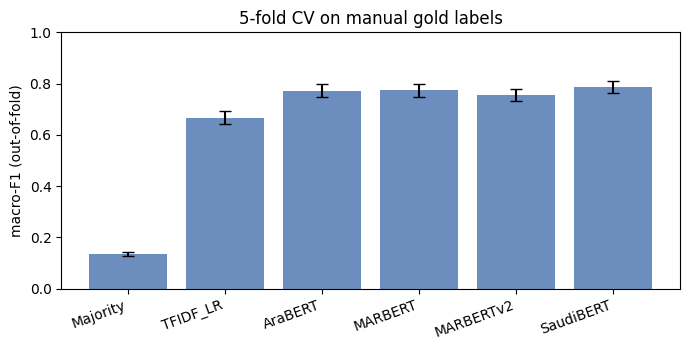

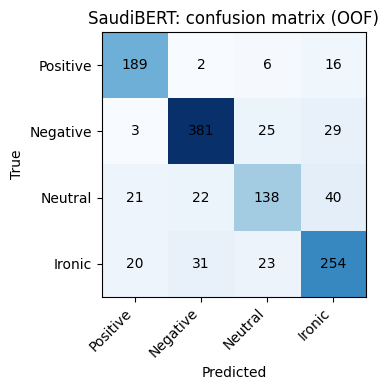

Best model: SaudiBERT


In [ ]:
fold_df = pd.DataFrame(fold_scores)
rows = []
for name, d in oof.items():
    fs = fold_df[fold_df.model == name]
    m = metrics(d.label, d.pred)
    lo, hi = bootstrap_ci(d.label, d.pred)
    rows.append({"model": name,
                 "accuracy (mean±std)": f"{fs.accuracy.mean():.3f} ± {fs.accuracy.std():.3f}",
                 "macro-F1 (mean±std)": f"{fs.macro_f1.mean():.3f} ± {fs.macro_f1.std():.3f}",
                 "OOF macro-F1": round(m["macro_f1"], 3),
                 "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                 "_mean": m["macro_f1"], "_lo": lo, "_hi": hi})
main = pd.DataFrame(rows)
print("MAIN RESULTS (5-fold CV on the 1,200 manual labels):")
display(main.drop(columns=["_mean", "_lo", "_hi"]))
main.drop(columns=["_mean", "_lo", "_hi"]).to_csv(f"{OUT_DIR}/results_main.csv", index=False)
fold_df.to_csv(f"{OUT_DIR}/results_per_fold.csv", index=False)

# per-class F1 (out-of-fold)
pc = pd.DataFrame({name: pd.Series(f1_score(d.label, d.pred, labels=LABELS, average=None, zero_division=0), index=LABELS)
                   for name, d in oof.items()}).round(3)
print("\nPer-class F1 (out-of-fold):"); display(pc); pc.to_csv(f"{OUT_DIR}/results_per_class.csv")

# per-source macro-F1 (out-of-fold)
ps = pd.DataFrame({name: {s: metrics(g.label, g.pred)["macro_f1"] for s, g in d.groupby("source")}
                   for name, d in oof.items()}).round(3)
print("Per-source macro-F1 (out-of-fold):"); display(ps); ps.to_csv(f"{OUT_DIR}/results_per_source.csv")

# bar chart with 95% CI
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(main))
ax.bar(x, main["_mean"], yerr=[main["_mean"] - main["_lo"], main["_hi"] - main["_mean"]], capsize=4, color="#6c8ebf")
ax.set_xticks(x); ax.set_xticklabels(main["model"], rotation=20, ha="right")
ax.set_ylabel("macro-F1 (out-of-fold)"); ax.set_ylim(0, 1); ax.set_title("5-fold CV on manual gold labels")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_model_comparison.png", dpi=200); plt.show()

# confusion matrix of the best model
best = main[main.model.isin(MODELS_TO_RUN)].set_index("model")["_mean"].idxmax()
d = oof[best]
cm = confusion_matrix(d.label, d.pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(LABELS, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(LABELS)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{best}: confusion matrix (OOF)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_confusion_best.png", dpi=200); plt.show()
print("Best model:", best)

## 8. Leave-one-source-out (LOSO)
Train on two sources, test on the third. Low scores here, compared with the in-source CV above, show that a model leans on source style. Note that each held-out source has its own class mix (for example Sa'7r is mostly Ironic), so macro-F1 is computed over the classes present.

In [ ]:
loso_rows = []
if RUN_LOSO:
    for name in MODELS_TO_RUN:
        for s in sorted(gold.source.unique()):
            te = gold[gold.source == s]
            trv = gold[gold.source != s]
            tr, dv = train_test_split(trv, test_size=DEV_FRAC, stratify=trv.label, random_state=SEED)
            outs = cached(f"{name}_loso_{s}", lambda: fit_predict(MODELS[name], tr, dv, {"test": te}, seed=SEED))
            pred = [LABELS[i] for i in outs["test"].argmax(1)]
            m = metrics(te.label, pred)
            loso_rows.append({"model": name, "held_out_source": s, "n_test": len(te),
                              "accuracy": round(m["accuracy"], 3), "macro_f1": round(m["macro_f1"], 3)})
            print(f"  {name} | held out {s}: macro-F1 {m['macro_f1']:.3f}")
    loso = pd.DataFrame(loso_rows)
    print("\nLOSO results:")
    display(loso.pivot(index="model", columns="held_out_source", values="macro_f1"))
    loso.to_csv(f"{OUT_DIR}/results_loso.csv", index=False)
else:
    print("RUN_LOSO = False, skipped.")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/655 [00:00<?, ? examples/s]

Map:   0%|          | 0/73 [00:00<?, ? examples/s]

{'eval_loss': 0.9797009229660034, 'eval_accuracy': 0.6575342465753424, 'eval_macro_f1': 0.5956262505002001, 'eval_runtime': 0.1046, 'eval_samples_per_second': 698.102, 'eval_steps_per_second': 19.126, 'epoch': 1.0}
{'loss': 1.1343, 'grad_norm': 6.076220989227295, 'learning_rate': 1.402439024390244e-05, 'epoch': 1.2195121951219512}
{'eval_loss': 0.8380803465843201, 'eval_accuracy': 0.6712328767123288, 'eval_macro_f1': 0.6346230158730158, 'eval_runtime': 0.1029, 'eval_samples_per_second': 709.561, 'eval_steps_per_second': 19.44, 'epoch': 2.0}
{'loss': 0.7325, 'grad_norm': 4.640743732452393, 'learning_rate': 7.926829268292685e-06, 'epoch': 2.4390243902439024}
{'eval_loss': 0.7793595790863037, 'eval_accuracy': 0.7123287671232876, 'eval_macro_f1': 0.6748575498575499, 'eval_runtime': 0.117, 'eval_samples_per_second': 624.057, 'eval_steps_per_second': 17.097, 'epoch': 3.0}
{'loss': 0.5487, 'grad_norm': 4.718730926513672, 'learning_rate': 1.8292682926829268e-06, 'epoch': 3.658536585365854}
{'e

Map:   0%|          | 0/472 [00:00<?, ? examples/s]

  AraBERT | held out Bank: macro-F1 0.646


... (66 outputs left out)

{'loss': 1.0571, 'grad_norm': 8.08774471282959, 'learning_rate': 1.5100000000000001e-05, 'epoch': 1.0}
{'eval_loss': 0.7328732013702393, 'eval_accuracy': 0.7159090909090909, 'eval_macro_f1': 0.7167483660130719, 'eval_runtime': 0.1025, 'eval_samples_per_second': 858.867, 'eval_steps_per_second': 19.52, 'epoch': 1.0}
{'loss': 0.552, 'grad_norm': 6.976249694824219, 'learning_rate': 1.0100000000000002e-05, 'epoch': 2.0}
{'eval_loss': 0.5786170363426208, 'eval_accuracy': 0.7727272727272727, 'eval_macro_f1': 0.7785714285714286, 'eval_runtime': 0.1051, 'eval_samples_per_second': 836.976, 'eval_steps_per_second': 19.022, 'epoch': 2.0}
{'loss': 0.3771, 'grad_norm': 11.495887756347656, 'learning_rate': 5.1e-06, 'epoch': 3.0}
{'eval_loss': 0.529662549495697, 'eval_accuracy': 0.7840909090909091, 'eval_macro_f1': 0.78428140610344, 'eval_runtime': 0.1033, 'eval_samples_per_second': 851.934, 'eval_steps_per_second': 19.362, 'epoch': 3.0}
{'loss': 0.2667, 'grad_norm': 2.2271907329559326, 'learning_rat

Map:   0%|          | 0/320 [00:00<?, ? examples/s]

  SaudiBERT | held out Telecom: macro-F1 0.731

LOSO results:


held_out_source,Bank,Sa7r,Telecom
model,,,
AraBERT,0.646,0.406,0.630
MARBERT,0.673,0.522,0.632
MARBERTv2,0.588,0.510,0.599
SaudiBERT,0.691,0.528,0.731


## 9. Ablation: gold only vs. gold + pseudo-labels
For each fold, the model trained on that fold's training data labels the unlabeled pool. We keep predictions with confidence >= `PSEUDO_MIN_CONF`, capped per (source, class) cell, add them to that fold's training set, retrain, and evaluate on the same untouched test fold. Pseudo-labels are never used for dev or test.

In [ ]:
abl = None
if RUN_ABLATION and ABLATION_MODEL in oof and len(pool_probs) == K_FOLDS:
    rows, silver_sizes = [], []
    aug_probs = {}
    for k in range(K_FOLDS):
        tr, dv, te = fold_split(k)
        P = pool_probs[k]
        cand = pool.copy()
        cand["label"] = [LABELS[i] for i in P.argmax(1)]
        cand["conf"] = P.max(1)
        cand = cand[cand.conf >= PSEUDO_MIN_CONF]
        silver = (cand.sort_values("conf", ascending=False)
                      .groupby(["source", "label"]).head(PSEUDO_PER_CELL)[["id", "source", "text", "label"]])
        silver_sizes.append(silver.groupby(["source", "label"]).size().rename(f"fold{k}"))
        train_aug = pd.concat([tr, silver], ignore_index=True)
        outs = cached(f"{ABLATION_MODEL}_ablation_fold{k}",
                      lambda: fit_predict(MODELS[ABLATION_MODEL], train_aug, dv, {"test": te}, seed=SEED + k))
        aug_probs[k] = outs["test"]
        pred = [LABELS[i] for i in outs["test"].argmax(1)]
        g = oof[ABLATION_MODEL]; g = g[g.fold == k]
        rows.append({"fold": k, "silver_rows": len(silver),
                     "gold_only_macro_f1": metrics(g.label, g.pred)["macro_f1"],
                     "gold_plus_silver_macro_f1": metrics(te.label, pred)["macro_f1"]})
        print(f"  fold {k}: +{len(silver):,} pseudo-labels | gold {rows[-1]['gold_only_macro_f1']:.3f} -> gold+silver {rows[-1]['gold_plus_silver_macro_f1']:.3f}")
    abl = pd.DataFrame(rows)
    abl["diff"] = abl.gold_plus_silver_macro_f1 - abl.gold_only_macro_f1
    display(abl.round(3))
    print(f"\nMean macro-F1: gold only {abl.gold_only_macro_f1.mean():.3f} ± {abl.gold_only_macro_f1.std():.3f} | "
          f"gold+silver {abl.gold_plus_silver_macro_f1.mean():.3f} ± {abl.gold_plus_silver_macro_f1.std():.3f} | "
          f"folds improved: {(abl['diff'] > 0).sum()}/{K_FOLDS}")
    print("Pseudo-labels added (fold 0), by source and class:")
    display(silver_sizes[0].unstack(fill_value=0))
    abl.to_csv(f"{OUT_DIR}/results_ablation.csv", index=False)
    record(f"{ABLATION_MODEL}_plus_silver", aug_probs)
else:
    print("Ablation skipped (RUN_ABLATION is False, or the ablation model was not run).")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at aubmindlab/bert-base-arabertv02-twitter and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/2524 [00:00<?, ? examples/s]

Map:   0%|          | 0/96 [00:00<?, ? examples/s]

{'loss': 0.8082, 'grad_norm': 6.019582748413086, 'learning_rate': 1.8449367088607598e-05, 'epoch': 0.31645569620253167}
{'loss': 0.3004, 'grad_norm': 5.029447555541992, 'learning_rate': 1.6867088607594938e-05, 'epoch': 0.6329113924050633}
{'loss': 0.2673, 'grad_norm': 1.540313959121704, 'learning_rate': 1.5284810126582278e-05, 'epoch': 0.9493670886075949}
{'eval_loss': 0.653743326663971, 'eval_accuracy': 0.8020833333333334, 'eval_macro_f1': 0.8122860255213196, 'eval_runtime': 0.1043, 'eval_samples_per_second': 920.476, 'eval_steps_per_second': 19.177, 'epoch': 1.0}
{'loss': 0.19, 'grad_norm': 1.4373104572296143, 'learning_rate': 1.3702531645569621e-05, 'epoch': 1.2658227848101267}
{'loss': 0.2078, 'grad_norm': 0.7399779558181763, 'learning_rate': 1.2120253164556963e-05, 'epoch': 1.5822784810126582}
{'loss': 0.1882, 'grad_norm': 6.39908504486084, 'learning_rate': 1.0537974683544305e-05, 'epoch': 1.8987341772151898}
{'eval_loss': 0.8064925670623779, 'eval_accuracy': 0.78125, 'eval_macro_

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

  fold 0: +1,660 pseudo-labels | gold 0.768 -> gold+silver 0.763


... (24 outputs left out)

,fold,silver_rows,gold_only_macro_f1,gold_plus_silver_macro_f1,diff
0,0,1660,0.768,0.763,-0.005
1,1,1628,0.782,0.781,-0.001
2,2,1754,0.740,0.740,0.000
3,3,1202,0.811,0.806,-0.005
4,4,1711,0.756,0.721,-0.036



Mean macro-F1: gold only 0.771 ± 0.027 | gold+silver 0.762 ± 0.033 | folds improved: 1/5
Pseudo-labels added (fold 0), by source and class:


label,Ironic,Negative,Neutral,Positive
source,,,,
Bank,87,150,150,150
Sa7r,150,150,83,150
Telecom,140,150,150,150


  AraBERT_plus_silver: out-of-fold accuracy 0.777 | macro-F1 0.763


## 10. Export

In [ ]:
import transformers, sklearn
summary = {"config": CFG, "label_distribution": gold.label.value_counts().reindex(LABELS).to_dict(),
           "n_gold": int(len(gold)), "main_results": main.drop(columns=["_mean", "_lo", "_hi"]).to_dict(orient="records"),
           "versions": {"python": platform.python_version(), "torch": torch.__version__,
                        "transformers": transformers.__version__, "sklearn": sklearn.__version__}}
with open(f"{OUT_DIR}/results_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=str)

zip_path = "gold_cv_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(OUT_DIR)):
        if fn.endswith((".csv", ".json", ".png")):
            z.write(os.path.join(OUT_DIR, fn), fn)
print("Zipped:", zip_path)
download(zip_path)

Zipped: gold_cv_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>